# Function 2 – Behavioral Anomaly Detection (Step 3)

> **Cleaned reading copy.** Same code and saved outputs as the hash-protected original
> `Function_2_Behavioral_Anomaly_Detection.ipynb`, which remains the research record.
> Running this copy re-executes Step 3 and rewrites `models/` and `outputs/` like the original.

Unsupervised novelty detection of unusual child-days from Component 1 (screen) and
Component 2 (language) daily features. Shared code: `src/behavioral_anomaly.py`.

> **Synthetic data only** (`behavioral_daily.csv`). Results compare models under the
> generator's assumptions; they do not establish real-world accuracy.

In [1]:
import json
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.metrics import (average_precision_score, precision_recall_curve,
                             roc_auc_score, ConfusionMatrixDisplay)

SEED = 42
np.random.seed(SEED)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "src" / "behavioral_anomaly.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src import behavioral_anomaly as BA
from src.behavioral_dataset import (BASELINE_WINDOW, FEATURE_CATALOG, LABEL_COLUMNS,
                                    MODEL_FEATURES)

DATA_PATH = ROOT / "data" / "behavioral_daily.csv"
META_PATH = ROOT / "data" / "behavioral_daily_metadata.json"
MODEL_DIR = BA.ARTIFACT_DIR

print("Component 4 root:", ROOT)
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

Component 4 root: E:\RP-J26-DS-316\component4_profiling_xai
scikit-learn 1.6.1 | pandas 3.0.3 | numpy 2.4.6


## 1. Data preparation

`behavioral_daily.csv` is read only; its SHA-256 is checked against the generator's metadata.

In [2]:
import hashlib

meta = json.loads(META_PATH.read_text(encoding="utf-8"))
sha = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
assert sha == meta["sha256"]["daily"], "behavioral_daily.csv differs from the generated dataset"

df = pd.read_csv(DATA_PATH)
df["date"] = pd.to_datetime(df["date"])
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns  (SHA-256 verified)")
print("Children:", df["child_id"].nunique(), "| days per child:", df.groupby("child_id").size().unique(),
      "| period:", df["date"].min().date(), "to", df["date"].max().date())
print("\nDisclaimer from the generator:\n ", meta["disclaimer"])
df.head()

Shape: 3,600 rows x 69 columns  (SHA-256 verified)
Children: 40 | days per child: [90] | period: 2026-07-01 to 2026-09-28

Disclaimer from the generator:
  Synthetic data. Event shapes follow the Component 1 incident sample and the Component 2 Verdict.to_record() sample; all rates, mixes and anomaly patterns are assumptions. Not real children, not an accuracy sample, not a real-world distribution.


,child_id,date,day_index,split,persona,child_id_source,demo_only,screen_monitor_observed,screen_incidents,screen_uncertain_groups,screen_flagged_frames,screen_flagged_seconds,screen_max_confidence,screen_mean_confidence,screen_night_incidents,screen_violence_incidents,screen_explicit_visual_incidents,screen_self_harm_imagery_incidents,screen_unknown_flagged_incidents,screen_blocked_incidents,screen_blurred_incidents,screen_escalated_incidents,screen_dismissed_incidents,language_monitor_observed,language_alert_records,language_flags,language_threat_flags,language_hate_identity_flags,language_bullying_flags,language_sexual_harassment_flags,language_self_harm_flags,language_grooming_flags,language_profanity_flags,language_urgent_flags,language_block_rung_flags,language_blocked_flags,language_max_risk,language_mean_risk,language_night_flags,language_screen_text_flags,language_audio_flags,language_typed_flags,language_distinct_apps,language_distinct_app_categories,total_risk_events,night_risk_events,is_weekend,baseline_ready,total_risk_events_prev14d_mean,total_risk_events_prev14d_z,language_flags_prev14d_mean,language_flags_prev14d_z,screen_incidents_prev14d_mean,screen_incidents_prev14d_z,night_risk_events_prev14d_mean,night_risk_events_prev14d_z,language_urgent_flags_prev14d_mean,language_urgent_flags_prev14d_z,language_bullying_flags_prev14d_mean,language_bullying_flags_prev14d_z,language_grooming_flags_prev14d_mean,language_grooming_flags_prev14d_z,language_self_harm_flags_prev14d_mean,language_self_harm_flags_prev14d_z,screen_blocked_incidents_prev14d_mean,screen_blocked_incidents_prev14d_z,is_anomaly,anomaly_type,episode_id
0,C001,2026-07-01,1,train,P1_PROTECT,record,False,True,0,0,0,0,0.0,0.0,0,0,0,0,0,0,0,0,0,True,0,0,0,0,0,0,0,0,0,0,0,0,0.0000,0.0000,0,0,0,0,0,0,0,0,False,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,none,NaN
1,C001,2026-07-02,2,train,P1_PROTECT,record,False,True,0,0,0,0,0.0,0.0,0,0,0,0,0,0,0,0,0,True,0,0,0,0,0,0,0,0,0,0,0,0,0.0000,0.0000,0,0,0,0,0,0,0,0,False,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,none,NaN
2,C001,2026-07-03,3,train,P1_PROTECT,record,False,True,0,0,0,0,0.0,0.0,0,0,0,0,0,0,0,0,0,True,0,0,0,0,0,0,0,0,0,0,0,0,0.0000,0.0000,0,0,0,0,0,0,0,0,False,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,none,NaN
3,C001,2026-07-04,4,train,P1_PROTECT,record,False,True,0,0,0,0,0.0,0.0,0,0,0,0,0,0,0,0,0,True,0,0,0,0,0,0,0,0,0,0,0,0,0.0000,0.0000,0,0,0,0,0,0,0,0,True,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,none,NaN
4,C001,2026-07-05,5,train,P1_PROTECT,record,False,True,0,0,0,0,0.0,0.0,0,0,0,0,0,0,0,0,0,True,1,1,1,0,0,0,0,0,0,0,0,0,0.6171,0.6171,0,0,1,0,1,1,1,0,True,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,none,NaN


### 1.1 Data types and missing values

In [3]:
dtype_summary = df.dtypes.astype(str).value_counts().rename_axis("dtype").reset_index(name="columns")
display(dtype_summary)

missing = df.isna().sum()
missing = missing[missing > 0]
print(f"Columns with missing values: {len(missing)}")
display(pd.DataFrame({"missing": missing,
                      "missing_in_train": df[df.split == "train"][missing.index].isna().sum(),
                      "missing_in_val": df[df.split == "validation"][missing.index].isna().sum(),
                      "missing_in_test": df[df.split == "test"][missing.index].isna().sum()}))

,dtype,columns
0,int64,35
1,float64,22
2,str,6
3,bool,5
4,datetime64[us],1


Columns with missing values: 19


,missing,missing_in_train,missing_in_val,missing_in_test
total_risk_events_prev14d_mean,280,280,0,0
total_risk_events_prev14d_z,280,280,0,0
language_flags_prev14d_mean,280,280,0,0
language_flags_prev14d_z,280,280,0,0
screen_incidents_prev14d_mean,280,280,0,0
screen_incidents_prev14d_z,280,280,0,0
night_risk_events_prev14d_mean,280,280,0,0
night_risk_events_prev14d_z,280,280,0,0
language_urgent_flags_prev14d_mean,280,280,0,0
language_urgent_flags_prev14d_z,280,280,0,0


Missing values: `episode_id` (label, normal days) and the 18 baseline columns on each
child's first 7 days (280 training rows). Validation and test have none.

### 1.2 Class distribution and chronological splits

Days 1–56 train, 57–73 validation, 74–90 test (same for every child).

,rows,anomaly_days,first_date,last_date,anomaly_rate_%
split,,,,,
train,2240,66,2026-07-01,2026-08-25,2.95
validation,680,49,2026-08-26,2026-09-11,7.21
test,680,53,2026-09-12,2026-09-28,7.79


split,train,validation,test
anomaly_type,,,
bullying_run,15,16,19
grooming_burst,19,15,15
late_night_violence,16,7,9
none,2174,631,627
self_harm_day,12,6,6
volume_spike,4,5,4


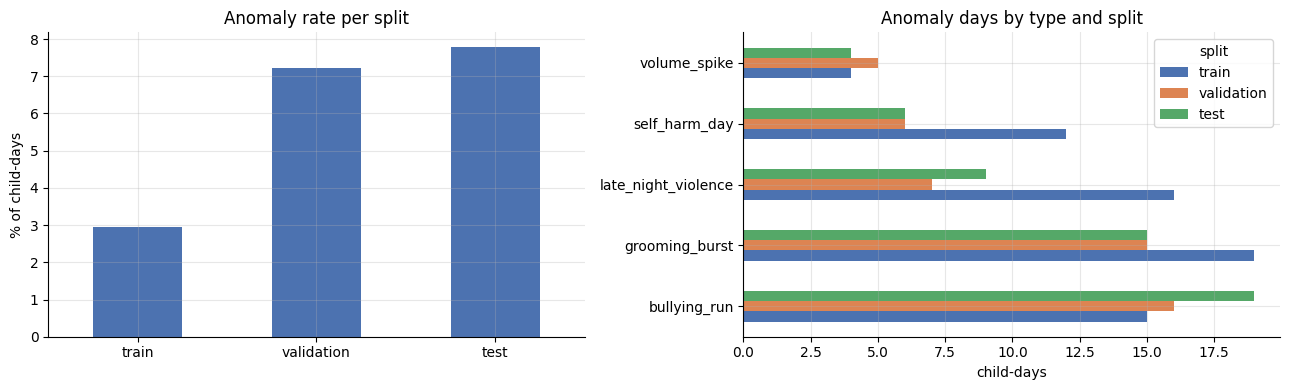

In [4]:
split_order = ["train", "validation", "test"]
split_summary = (df.groupby("split")
                   .agg(rows=("is_anomaly", "size"), anomaly_days=("is_anomaly", "sum"),
                        first_date=("date", "min"), last_date=("date", "max"))
                   .reindex(split_order))
split_summary["anomaly_rate_%"] = (100 * split_summary.anomaly_days / split_summary.rows).round(2)
display(split_summary)

type_by_split = pd.crosstab(df["anomaly_type"], df["split"]).reindex(columns=split_order)
display(type_by_split)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
split_summary["anomaly_rate_%"].plot.bar(ax=axes[0], color="#4C72B0")
axes[0].set(title="Anomaly rate per split", ylabel="% of child-days", xlabel="")
axes[0].tick_params(axis="x", rotation=0)
type_by_split.drop(index="none").plot.barh(ax=axes[1], color=["#4C72B0", "#DD8452", "#55A868"])
axes[1].set(title="Anomaly days by type and split", xlabel="child-days", ylabel="")
plt.tight_layout(); plt.show()

Anomalies: ~4.7 % of child-days (66 / 49 / 53 in train / validation / test). About 50
positives per split, so metrics are uncertain; the test result has a bootstrap interval.

### 1.3 Feature distributions (training data, log(1 + x))

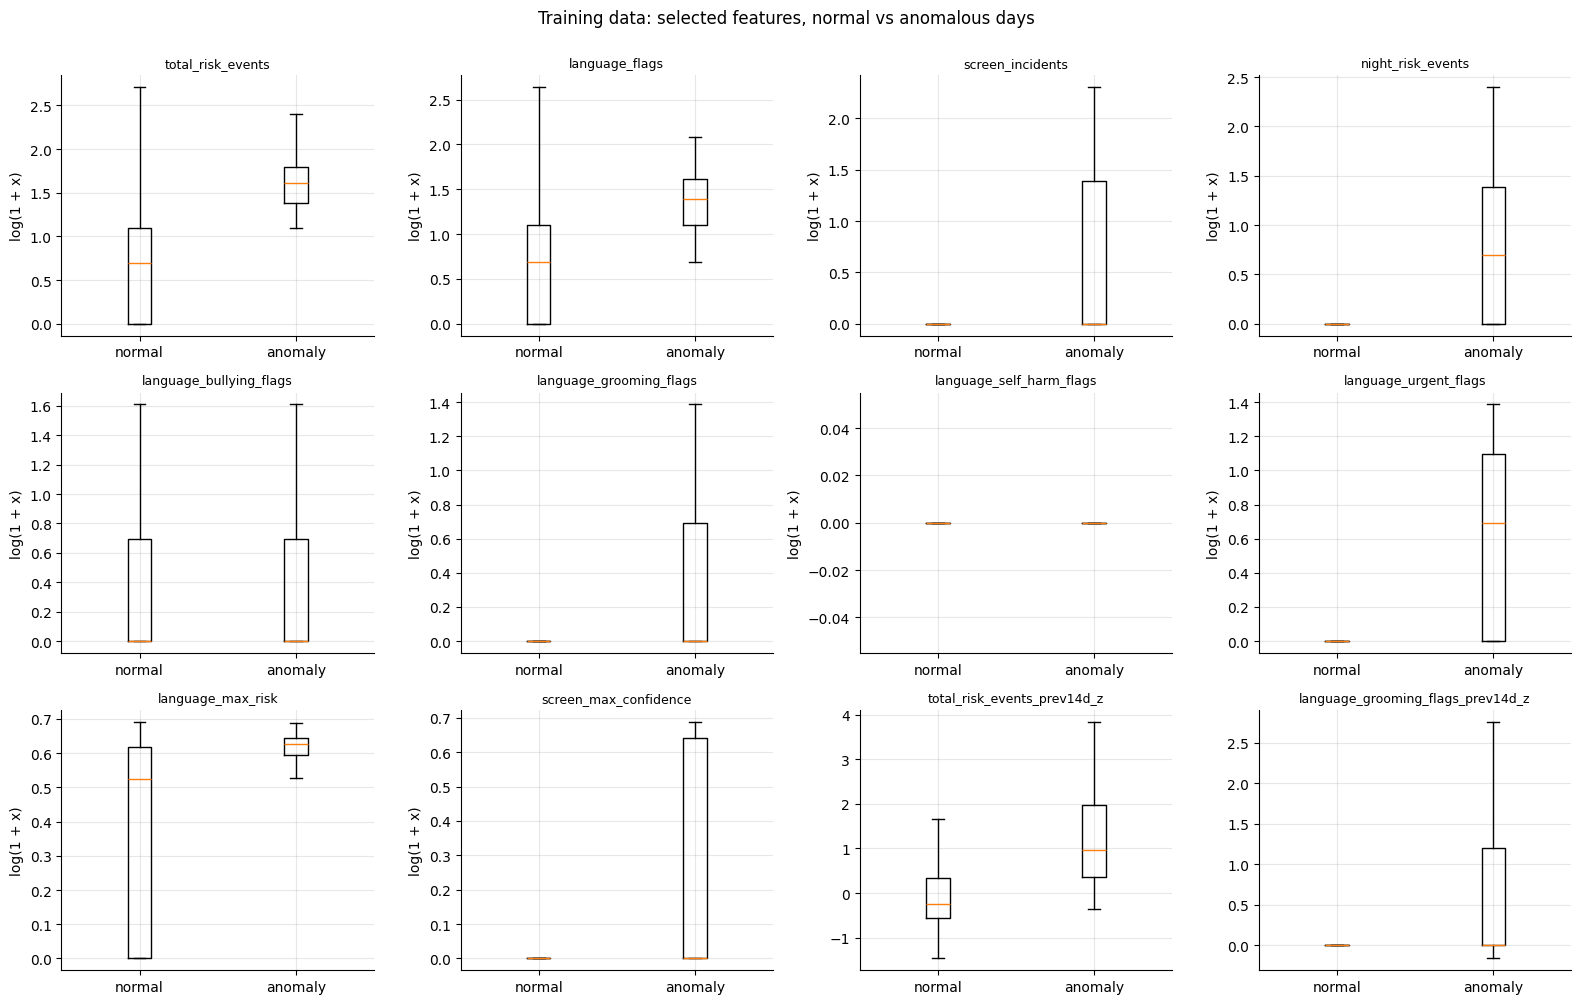

,mean,std,min,50%,max,share_zero
screen_incidents,0.460,1.141,0.000,0.000,9.000,0.796
screen_flagged_frames,1.615,4.158,0.000,0.000,37.000,0.796
screen_flagged_seconds,4.038,10.412,0.000,0.000,89.000,0.796
screen_max_confidence,0.165,0.329,0.000,0.000,0.990,0.796
screen_mean_confidence,0.146,0.291,0.000,0.000,0.960,0.796
screen_night_incidents,0.058,0.471,0.000,0.000,8.000,0.978
screen_blocked_incidents,0.178,0.596,0.000,0.000,7.000,0.882
screen_escalated_incidents,0.067,0.299,0.000,0.000,4.000,0.943
screen_dismissed_incidents,0.096,0.354,0.000,0.000,3.000,0.921
language_flags,1.161,1.565,0.000,1.000,13.000,0.448


In [5]:
train_all = df[df.split == "train"]
show = ["total_risk_events", "language_flags", "screen_incidents", "night_risk_events",
        "language_bullying_flags", "language_grooming_flags", "language_self_harm_flags",
        "language_urgent_flags", "language_max_risk", "screen_max_confidence",
        "total_risk_events_prev14d_z", "language_grooming_flags_prev14d_z"]

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.ravel(), show):
    groups = [train_all.loc[train_all.is_anomaly == k, col].dropna() for k in (0, 1)]
    if col.endswith("_z"):
        ax.boxplot(groups, tick_labels=["normal", "anomaly"], showfliers=False)
    else:
        ax.boxplot([np.log1p(g.clip(lower=0)) for g in groups], tick_labels=["normal", "anomaly"],
                   showfliers=False)
        ax.set_ylabel("log(1 + x)")
    ax.set_title(col, fontsize=9)
plt.suptitle("Training data: selected features, normal vs anomalous days", y=1.0)
plt.tight_layout(); plt.show()

desc = train_all[MODEL_FEATURES].astype(float).describe().T[["mean", "std", "min", "50%", "max"]]
desc["share_zero"] = (train_all[MODEL_FEATURES].astype(float) == 0).mean()
desc.round(3)

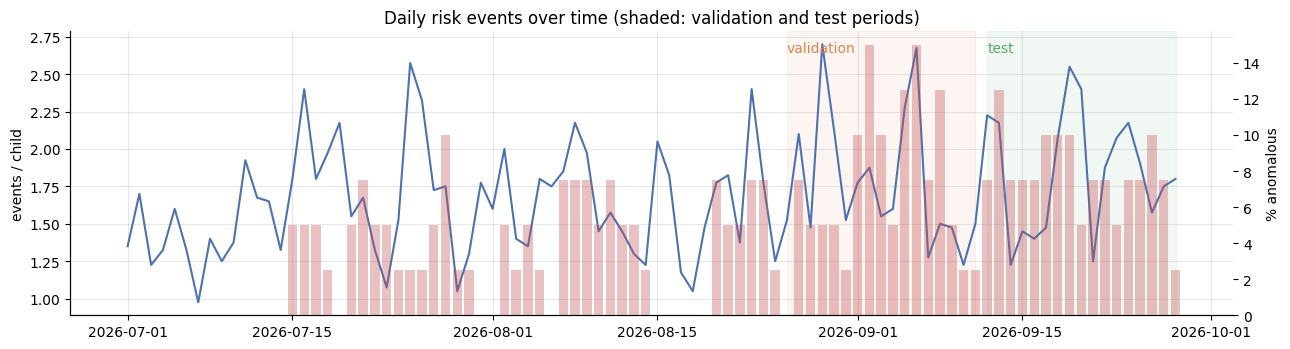

In [6]:
fig, ax = plt.subplots(figsize=(13, 3.6))
daily_rate = df.groupby("date").agg(events=("total_risk_events", "mean"), anomaly=("is_anomaly", "mean"))
ax.plot(daily_rate.index, daily_rate["events"], color="#4C72B0", label="mean total_risk_events per child")
ax2 = ax.twinx()
ax2.bar(daily_rate.index, daily_rate["anomaly"] * 100, color="#C44E52", alpha=0.35, label="% anomalous children")
for name, color in [("validation", "#DD8452"), ("test", "#55A868")]:
    d = df.loc[df.split == name, "date"]
    ax.axvspan(d.min(), d.max(), color=color, alpha=0.08)
    ax.text(d.min(), ax.get_ylim()[1] * 0.95, name, color=color)
ax.set(title="Daily risk events over time (shaded: validation and test periods)", ylabel="events / child")
ax2.set_ylabel("% anomalous"); ax2.grid(False)
plt.tight_layout(); plt.show()

### 1.4 Dataset provenance and limitations

Generator `src/behavioral_synthetic.py` v1.0.0, seed 42: 40 children × 90 days
(1 Jul – 28 Sep 2026, Asia/Colombo). Normal C1/C2 events per child, then injected episodes
(grooming burst, late-night violence, bullying run, self-harm day, volume spike) as extra
events; C2's `decide()` filters checks; the Step 1 builder makes the daily features. A day
is anomalous when an injected event survives on it.

Limitations: all rates and patterns are assumptions; anomalies only *add* events; only
C1's violence model is live; few positives per split; no device gaps.

## 2. Feature engineering and selection

- **Set A – daily:** C1 screen, C2 language, combined counts, `is_weekend`.
- **Set B – full:** all `MODEL_FEATURES` = Set A + 14-day per-child baseline means and z-scores.

In [7]:
source_of = {d: src for _, d, src, _ in FEATURE_CATALOG}

def feature_group(f):
    if f in BA.BASELINE_FEATURES:
        return "14-day baseline"
    if f.startswith("screen_"):
        return "C1 screen monitoring"
    if f.startswith("language_"):
        return "C2 language monitoring"
    if f == "is_weekend":
        return "calendar"
    return "combined daily risk"

feature_table = pd.DataFrame({
    "feature": BA.FEATURE_SET_B,
    "group": [feature_group(f) for f in BA.FEATURE_SET_B],
    "in_set_A": [f in BA.FEATURE_SET_A for f in BA.FEATURE_SET_B],
    "source_fields": [source_of[f] for f in BA.FEATURE_SET_B],
})
group_counts = pd.crosstab(feature_table["group"], feature_table["in_set_A"].map({True: "Set A and B", False: "Set B only"}))
display(group_counts)
print(f"Set A: {len(BA.FEATURE_SET_A)} features | Set B: {len(BA.FEATURE_SET_B)} features")

assert len(BA.FEATURE_SET_B) == len(MODEL_FEATURES) == 45
assert set(BA.FEATURE_SET_A) | set(BA.BASELINE_FEATURES) == set(BA.FEATURE_SET_B)
assert not set(BA.FEATURE_SET_A) & set(BA.BASELINE_FEATURES)
forbidden = set(BA.NON_FEATURE_COLUMNS)
assert not forbidden & set(BA.FEATURE_SET_B), "metadata / label column in a feature set"
print("Excluded from every feature set:", sorted(forbidden))
feature_table

in_set_A,Set A and B,Set B only
group,,
14-day baseline,0,18
C1 screen monitoring,9,0
C2 language monitoring,15,0
calendar,1,0
combined daily risk,2,0


Set A: 27 features | Set B: 45 features
Excluded from every feature set: ['anomaly_type', 'baseline_ready', 'child_id', 'child_id_source', 'date', 'day_index', 'demo_only', 'episode_id', 'is_anomaly', 'persona', 'split']


,feature,group,in_set_A,source_fields
0,screen_incidents,C1 screen monitoring,True,incident_id | session_id + duration_visible_ms
1,screen_flagged_frames,C1 screen monitoring,True,frames_flagged | payload count
2,screen_flagged_seconds,C1 screen monitoring,True,duration_s | ended_at - started_at | duration_...
3,screen_max_confidence,C1 screen monitoring,True,max_confidence | confidence_score
4,screen_mean_confidence,C1 screen monitoring,True,mean_confidence | confidence_score
5,screen_night_incidents,C1 screen monitoring,True,started_at
6,screen_blocked_incidents,C1 screen monitoring,True,action = block
7,screen_escalated_incidents,C1 screen monitoring,True,escalated
8,screen_dismissed_incidents,C1 screen monitoring,True,dismissed_by_child
9,language_flags,C2 language monitoring,True,rung != L0 and not abstained


**Set A = 27 features** (9 screen + 15 language + 2 combined + `is_weekend`), **Set B = 45**.

### 2.1 Feature checks (training data only)

Constant columns, exact duplicates, pairs with |r| ≥ 0.95.

In [8]:
train_rows = df[(df.split == "train")]
checks = {name: BA.check_features(train_rows, feats) for name, feats in BA.FEATURE_SETS.items()}
for name, rep in checks.items():
    print(f"{name}: constant = {rep['constant']} | exact duplicates = {rep['duplicates']} | "
          f"pairs with |r| >= 0.95: {len(rep['high_corr'])}")
display(checks["B_full"]["high_corr"].round(4))

A_daily: constant = [] | exact duplicates = [] | pairs with |r| >= 0.95: 6
B_full: constant = [] | exact duplicates = [] | pairs with |r| >= 0.95: 6


,feature_1,feature_2,abs_r
0,screen_flagged_frames,screen_flagged_seconds,0.9970
1,screen_max_confidence,screen_mean_confidence,0.9963
2,language_max_risk,language_mean_risk,0.9954
3,language_distinct_apps,language_distinct_app_categories,0.9690
4,screen_incidents,screen_flagged_frames,0.9688
5,screen_incidents,screen_flagged_seconds,0.9648


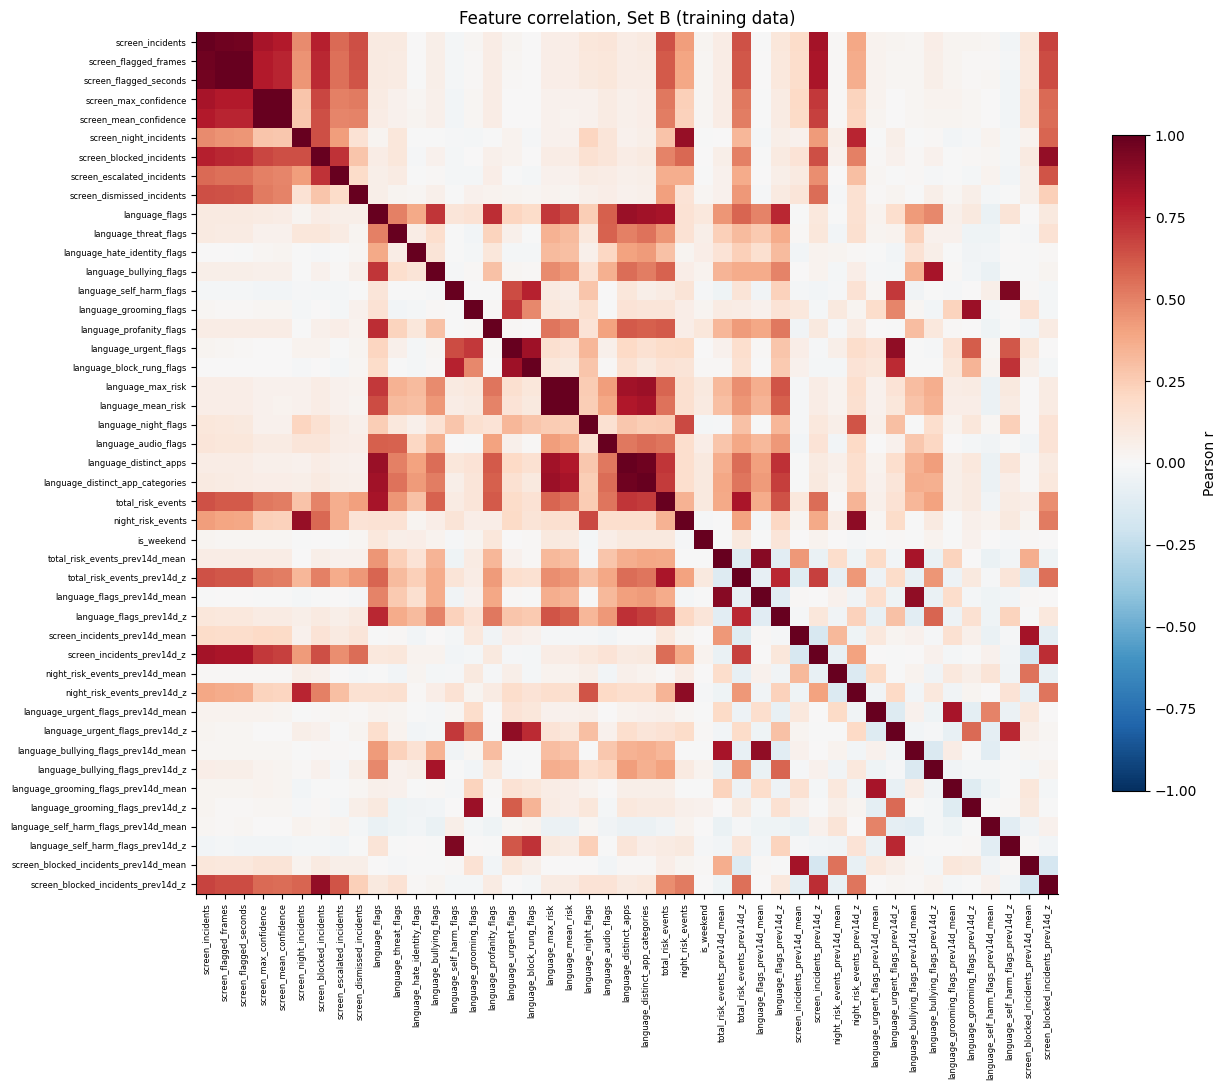

In [9]:
corr = BA.feature_matrix(train_rows, BA.FEATURE_SET_B).corr()
fig, ax = plt.subplots(figsize=(13, 11))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90, fontsize=6)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=6)
ax.grid(False)
plt.colorbar(im, ax=ax, fraction=0.03, label="Pearson r")
ax.set_title("Feature correlation, Set B (training data)")
plt.tight_layout(); plt.show()

**Decision:** no constant or duplicate columns; six correlated pairs kept (different
properties, not exact copies).

### 2.2 Leakage checks (training data only)

Labels/metadata excluded; baselines recomputed from earlier days only; single-feature ROC-AUC.

In [10]:
chk = df.sort_values(["child_id", "date"]).copy()
prev = chk.groupby("child_id")["total_risk_events"].shift(1)
recomputed = (prev.groupby(chk["child_id"])
                  .rolling(BASELINE_WINDOW, min_periods=7).mean()
                  .reset_index(level=0, drop=True))
diff = (recomputed - chk[f"total_risk_events_prev{BASELINE_WINDOW}d_mean"]).abs().max()
print(f"Max |recomputed - stored| for total_risk_events_prev14d_mean: {diff:.2e}  (earlier days only)")
assert diff < 1e-9

Xtr_all = BA.feature_matrix(train_rows, BA.FEATURE_SET_B)
auc = {f: roc_auc_score(train_rows.is_anomaly, Xtr_all[f].fillna(Xtr_all[f].median()))
       for f in BA.FEATURE_SET_B}
auc = pd.Series(auc).sort_values(ascending=False).rename("train_ROC_AUC")
print("Highest single-feature ROC-AUC:", auc.round(3).head(8).to_dict())
print("Any feature with AUC >= 0.99?", bool((auc >= 0.99).any()))

Max |recomputed - stored| for total_risk_events_prev14d_mean: 4.62e-10  (earlier days only)
Highest single-feature ROC-AUC: {'total_risk_events': 0.859, 'total_risk_events_prev14d_z': 0.853, 'language_flags_prev14d_z': 0.825, 'language_flags': 0.804, 'night_risk_events': 0.797, 'language_urgent_flags_prev14d_z': 0.77, 'night_risk_events_prev14d_z': 0.768, 'language_urgent_flags': 0.766}
Any feature with AUC >= 0.99? False


No leakage: best single-feature AUC 0.859; risk counts are signal by design.

## 3. Splitting and preprocessing

- Chronological splits, no shuffling.
- Fitting rows: normal training days with a baseline (same rows for both sets). Labels only select normal days.
- Pipeline fitted on those rows: median imputer → `StandardScaler` → detector.
- Test rows are not loaded until Section 7.

In [11]:
fit_rows = df[(df.split == "train") & df.baseline_ready & (df.is_anomaly == 0)].copy()
val = df[df.split == "validation"].copy()
y_val = val["is_anomaly"].to_numpy()

FEATURES = {name: BA.clean_feature_list(fit_rows, feats) for name, feats in BA.FEATURE_SETS.items()}
for name, feats in FEATURES.items():
    assert feats == BA.FEATURE_SETS[name], "a column was dropped as constant / duplicate"

excluded = df[df.split == "train"]
print(f"Training-period rows:                       {len(excluded):,}")
print(f"  - first 7 days per child (no baseline):   {(~excluded.baseline_ready).sum():,}")
print(f"  - anomalous days (kept out of fitting):   {(excluded.baseline_ready & (excluded.is_anomaly == 1)).sum():,}")
print(f"  = fitting rows (normal, baseline ready):  {len(fit_rows):,}")
print(f"Validation rows: {len(val):,}  ({y_val.sum()} anomalous)")
print(f"Fitting period ends {fit_rows.date.max().date()} < validation starts {val.date.min().date()}")
assert fit_rows.date.max() < val.date.min()
print({k: len(v) for k, v in FEATURES.items()})

Training-period rows:                       2,240
  - first 7 days per child (no baseline):   280
  - anomalous days (kept out of fitting):   66
  = fitting rows (normal, baseline ready):  1,894
Validation rows: 680  (49 anomalous)
Fitting period ends 2026-08-25 < validation starts 2026-08-26
{'A_daily': 27, 'B_full': 45}


## 4. Model training

Isolation Forest and One-Class SVM (RBF) on Set A and Set B → 4 configurations.
Anomaly score = `-score_samples` (higher = more unusual). Below: untuned baselines.

In [12]:
QUANTILES = np.round(np.r_[np.arange(0.90, 0.99, 0.01), np.arange(0.990, 0.9991, 0.001)], 3)
CONFIGS = [(alg, fs) for alg in BA.ALGORITHMS for fs in FEATURES]
DEFAULT_PARAMS = {"isolation_forest": {"n_estimators": 100, "max_samples": "auto"},
                  "one_class_svm": {"nu": 0.05, "gamma": "scale"}}

def run_config(alg, fs, params):
    feats = FEATURES[fs]
    pipe = BA.build_pipeline(alg, params, seed=SEED).fit(BA.feature_matrix(fit_rows, feats))
    s_fit = BA.anomaly_scores(pipe, BA.feature_matrix(fit_rows, feats))
    s_val = BA.anomaly_scores(pipe, BA.feature_matrix(val, feats))
    best, table = BA.tune_threshold(s_fit, s_val, y_val, QUANTILES)
    return pipe, s_fit, s_val, best, table

rows = []
for alg, fs in CONFIGS:
    _, _, s_val, best, _ = run_config(alg, fs, DEFAULT_PARAMS[alg])
    rows.append({"algorithm": alg, "feature_set": fs, "params": DEFAULT_PARAMS[alg],
                 "val_PR_AUC": average_precision_score(y_val, s_val),
                 **{k: best[k] for k in ("quantile", "precision", "recall", "f1")}})
pd.DataFrame(rows).round(3)

,algorithm,feature_set,params,val_PR_AUC,quantile,precision,recall,f1
0,isolation_forest,A_daily,"{'n_estimators': 100, 'max_samples': 'auto'}",0.398,0.950,0.385,0.510,0.439
1,isolation_forest,B_full,"{'n_estimators': 100, 'max_samples': 'auto'}",0.394,0.970,0.462,0.490,0.475
2,one_class_svm,A_daily,"{'nu': 0.05, 'gamma': 'scale'}",0.598,0.994,0.564,0.633,0.596
3,one_class_svm,B_full,"{'nu': 0.05, 'gamma': 'scale'}",0.591,0.999,0.509,0.571,0.538


## 5. Hyperparameter and threshold tuning (validation only)

- Threshold = quantile (0.90–0.999) of normal training scores, chosen by validation F1; ties → higher quantile.
- Isolation Forest: `n_estimators` {100, 300}, `max_samples` {128, 256, 512, 1024}, `max_features` {0.5, 0.75, 1.0}.
- One-Class SVM: `nu` {0.005, 0.01, 0.02, 0.05, 0.1}, `gamma` {scale, 0.0003, 0.001, 0.003, 0.01, 0.03}.
- Per configuration: best validation F1, ties → validation PR-AUC.

In [13]:
from itertools import product

GRIDS = {
    "isolation_forest": [{"n_estimators": n, "max_samples": m, "max_features": f}
                         for n, m, f in product([100, 300], [128, 256, 512, 1024], [0.5, 0.75, 1.0])],
    "one_class_svm": [{"nu": nu, "gamma": g}
                      for nu, g in product([0.005, 0.01, 0.02, 0.05, 0.1], ["scale", 0.0003, 0.001, 0.003, 0.01, 0.03])],
}

grid_rows = []
for alg, fs in CONFIGS:
    for params in GRIDS[alg]:
        _, _, s_val, best, _ = run_config(alg, fs, params)
        grid_rows.append({"algorithm": alg, "feature_set": fs, "params": json.dumps(params),
                          "val_PR_AUC": average_precision_score(y_val, s_val), **best})
grid = pd.DataFrame(grid_rows)
print(f"{len(grid)} grid points evaluated on validation")

best_per_config = (grid.sort_values(["f1", "val_PR_AUC"], ascending=False)
                       .groupby(["algorithm", "feature_set"], sort=False).head(1)
                       .reset_index(drop=True))
best_per_config[["algorithm", "feature_set", "params", "quantile", "threshold",
                 "precision", "recall", "f1", "val_PR_AUC"]].round(4)

108 grid points evaluated on validation


,algorithm,feature_set,params,quantile,threshold,precision,recall,f1,val_PR_AUC
0,one_class_svm,A_daily,"{""nu"": 0.01, ""gamma"": 0.001}",0.970,-12.5158,0.6818,0.6122,0.6452,0.5951
1,one_class_svm,B_full,"{""nu"": 0.05, ""gamma"": 0.01}",0.995,-3.7689,0.7879,0.5306,0.6341,0.6059
2,isolation_forest,B_full,"{""n_estimators"": 300, ""max_samples"": 1024, ""ma...",0.991,0.5860,0.7500,0.4898,0.5926,0.5493
3,isolation_forest,A_daily,"{""n_estimators"": 100, ""max_samples"": 1024, ""ma...",0.970,0.5841,0.5510,0.5510,0.5510,0.5160


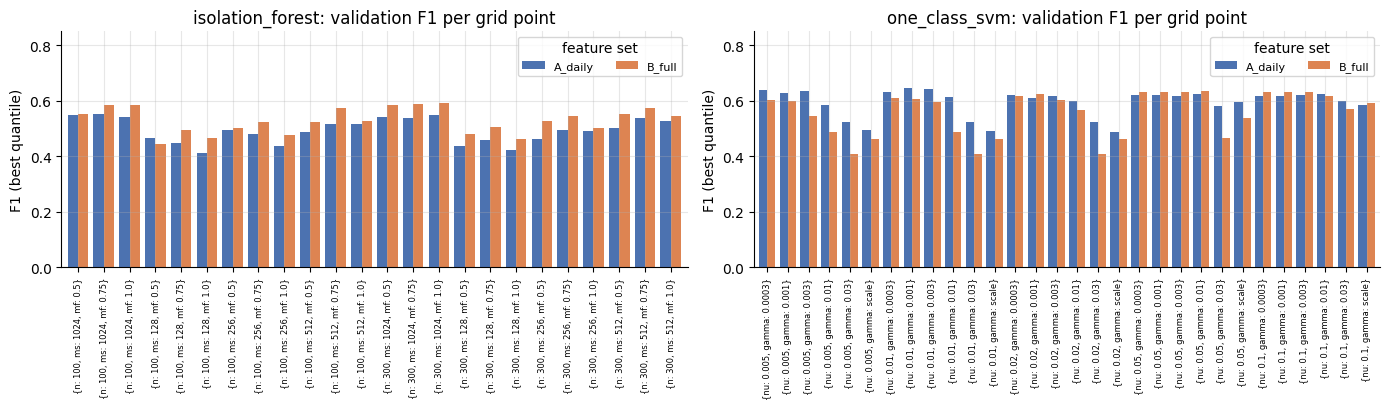

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for (alg, ax) in zip(BA.ALGORITHMS, axes):
    sub = grid[grid.algorithm == alg].copy()
    sub["label"] = sub["params"].str.replace('"', "").str.replace("n_estimators", "n").str.replace(
        "max_samples", "ms").str.replace("max_features", "mf")
    piv = sub.pivot(index="label", columns="feature_set", values="f1")
    piv.plot.bar(ax=ax, width=0.8, color=["#4C72B0", "#DD8452"])
    ax.set(title=f"{alg}: validation F1 per grid point", ylabel="F1 (best quantile)", xlabel="")
    ax.tick_params(axis="x", labelsize=6, rotation=90)
    ax.set_ylim(0, 0.85); ax.legend(title="feature set", ncol=2, loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()

### 5.1 Tuned configurations on validation

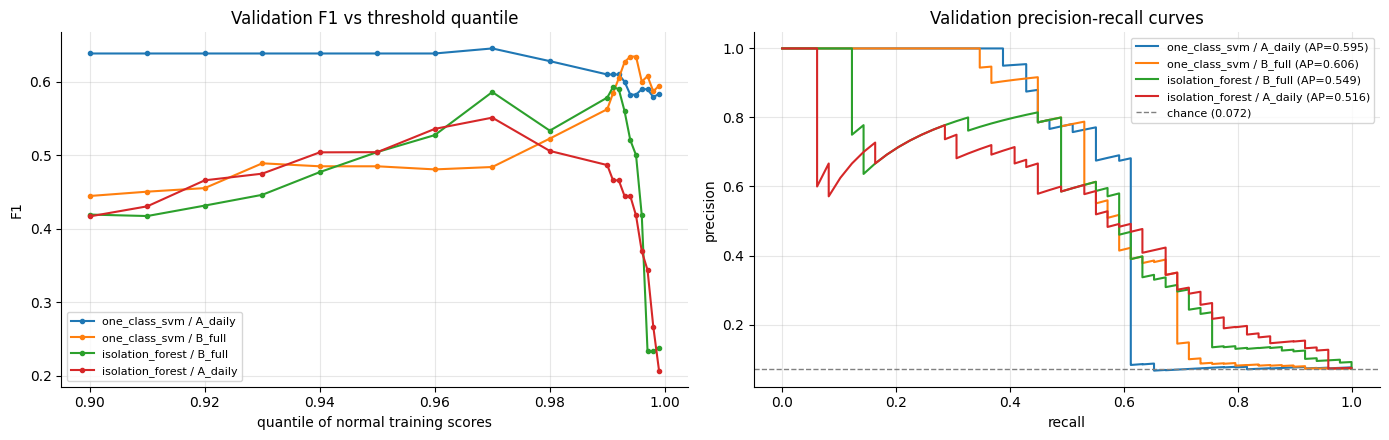

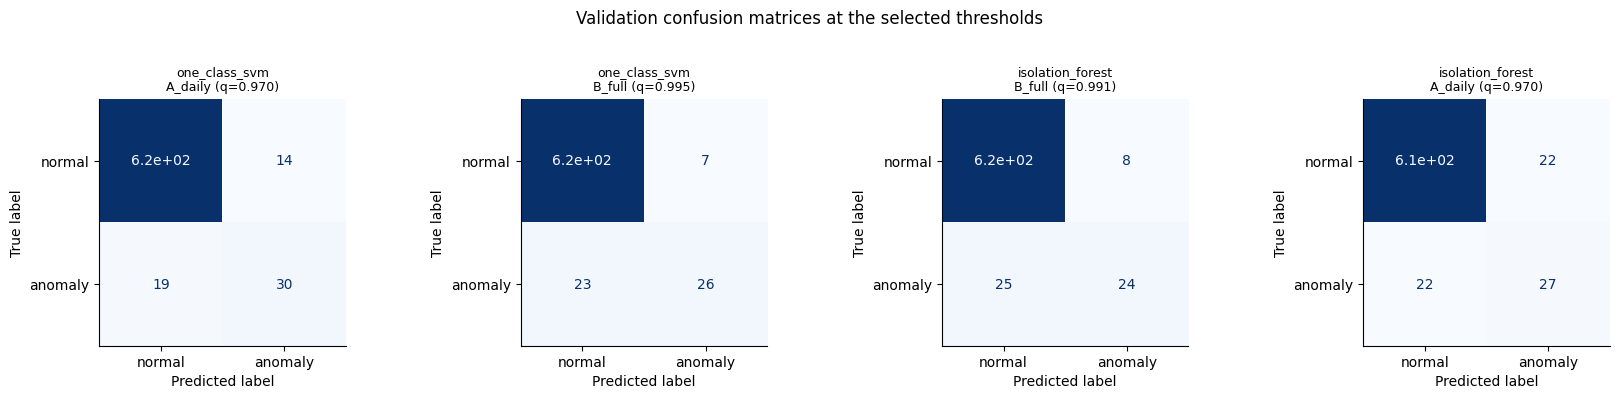

In [15]:
tuned = {}
for _, r in best_per_config.iterrows():
    params = json.loads(r["params"])
    pipe, s_fit, s_val, best, table = run_config(r["algorithm"], r["feature_set"], params)
    assert abs(best["f1"] - r["f1"]) < 1e-12
    tuned[(r["algorithm"], r["feature_set"])] = dict(pipe=pipe, params=params, s_fit=s_fit,
                                                     s_val=s_val, best=best, table=table)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for (alg, fs), t in tuned.items():
    axes[0].plot(t["table"]["quantile"], t["table"]["f1"], marker=".", label=f"{alg} / {fs}")
    p, rc, _ = precision_recall_curve(y_val, t["s_val"])
    axes[1].plot(rc, p, label=f"{alg} / {fs} (AP={average_precision_score(y_val, t['s_val']):.3f})")
axes[0].set(title="Validation F1 vs threshold quantile", xlabel="quantile of normal training scores", ylabel="F1")
axes[1].axhline(y_val.mean(), ls="--", color="grey", lw=1, label=f"chance ({y_val.mean():.3f})")
axes[1].set(title="Validation precision-recall curves", xlabel="recall", ylabel="precision")
for ax in axes: ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, ((alg, fs), t) in zip(axes, tuned.items()):
    b = t["best"]
    ConfusionMatrixDisplay(np.array([[b["tn"], b["fp"]], [b["fn"], b["tp"]]]),
                           display_labels=["normal", "anomaly"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{alg}\n{fs} (q={b['quantile']:.3f})", fontsize=9); ax.grid(False)
plt.suptitle("Validation confusion matrices at the selected thresholds", y=1.03)
plt.tight_layout(); plt.show()

## 6. Results – model comparison (validation)

Sorted by validation F1, then PR-AUC, then fewer features.

In [16]:
comparison = pd.DataFrame([{
    "algorithm": alg, "feature_set": fs, "n_features": len(FEATURES[fs]),
    "params": t["params"],
    "precision": t["best"]["precision"], "recall": t["best"]["recall"], "f1": t["best"]["f1"],
    "val_PR_AUC": average_precision_score(y_val, t["s_val"]),
    "threshold_quantile": t["best"]["quantile"], "selected_threshold": t["best"]["threshold"],
    "TP": t["best"]["tp"], "FP": t["best"]["fp"], "FN": t["best"]["fn"], "TN": t["best"]["tn"],
} for (alg, fs), t in tuned.items()])

comparison = comparison.sort_values(["f1", "val_PR_AUC", "n_features"],
                                    ascending=[False, False, True]).reset_index(drop=True)
comparison.insert(0, "rank", range(1, len(comparison) + 1))
(ROOT / "outputs").mkdir(exist_ok=True)
comparison.to_csv(ROOT / "outputs" / "behavioral_anomaly_validation_comparison.csv", index=False)
comparison.round(4)

,rank,algorithm,feature_set,n_features,params,precision,recall,f1,val_PR_AUC,threshold_quantile,selected_threshold,TP,FP,FN,TN
0,1,one_class_svm,A_daily,27,"{'nu': 0.01, 'gamma': 0.001}",0.6818,0.6122,0.6452,0.5951,0.970,-12.5158,30.0,14.0,19.0,617.0
1,2,one_class_svm,B_full,45,"{'nu': 0.05, 'gamma': 0.01}",0.7879,0.5306,0.6341,0.6059,0.995,-3.7689,26.0,7.0,23.0,624.0
2,3,isolation_forest,B_full,45,"{'n_estimators': 300, 'max_samples': 1024, 'ma...",0.7500,0.4898,0.5926,0.5493,0.991,0.5860,24.0,8.0,25.0,623.0
3,4,isolation_forest,A_daily,27,"{'n_estimators': 100, 'max_samples': 1024, 'ma...",0.5510,0.5510,0.5510,0.5160,0.970,0.5841,27.0,22.0,22.0,609.0


In [17]:
best_row = comparison.iloc[0]
BEST = (best_row["algorithm"], best_row["feature_set"])
best = tuned[BEST]
print("Selected configuration:", BEST)
print("Parameters:", best["params"])
print(f"Threshold: score > {best['best']['threshold']:.6f}  "
      f"(quantile {best['best']['quantile']:.3f} of normal training scores)")
print(f"Validation precision {best_row.precision:.3f} | recall {best_row.recall:.3f} | "
      f"F1 {best_row.f1:.3f} | PR-AUC {best_row.val_PR_AUC:.3f}")

per_type = {}
for (alg, fs), t in tuned.items():
    flagged = t["s_val"] > t["best"]["threshold"]
    per_type[f"{alg} / {fs}"] = pd.Series(flagged[y_val == 1]).groupby(
        val.loc[val.is_anomaly == 1, "anomaly_type"].to_numpy()).mean()
display(pd.DataFrame(per_type).round(2).rename_axis("validation recall by type"))

Selected configuration: ('one_class_svm', 'A_daily')
Parameters: {'nu': 0.01, 'gamma': 0.001}
Threshold: score > -12.515804  (quantile 0.970 of normal training scores)
Validation precision 0.682 | recall 0.612 | F1 0.645 | PR-AUC 0.595


,one_class_svm / A_daily,one_class_svm / B_full,isolation_forest / B_full,isolation_forest / A_daily
validation recall by type,,,,
bullying_run,0.06,0.00,0.06,0.06
grooming_burst,1.00,0.87,0.67,0.80
late_night_violence,0.86,0.86,0.86,0.86
self_harm_day,1.00,1.00,0.83,1.00
volume_spike,0.40,0.20,0.40,0.40


### 6.1 Interpretation

In [18]:
def describe(r):
    return (f"{r.algorithm} on {r.feature_set} ({r.n_features} features): F1 {r.f1:.3f}, "
            f"precision {r.precision:.3f}, recall {r.recall:.3f}, PR-AUC {r.val_PR_AUC:.3f}")

print("Best: ", describe(comparison.iloc[0]))
for _, r in comparison.iloc[1:].iterrows():
    print("Then:", describe(r))

for alg in BA.ALGORITHMS:
    a, b = (comparison.set_index(["algorithm", "feature_set"]).loc[(alg, fs)] for fs in ("A_daily", "B_full"))
    print(f"\n{alg}: Set B - Set A  F1 {b.f1 - a.f1:+.3f}, PR-AUC {b.val_PR_AUC - a.val_PR_AUC:+.3f}")

Best:  one_class_svm on A_daily (27 features): F1 0.645, precision 0.682, recall 0.612, PR-AUC 0.595
Then: one_class_svm on B_full (45 features): F1 0.634, precision 0.788, recall 0.531, PR-AUC 0.606
Then: isolation_forest on B_full (45 features): F1 0.593, precision 0.750, recall 0.490, PR-AUC 0.549
Then: isolation_forest on A_daily (27 features): F1 0.551, precision 0.551, recall 0.551, PR-AUC 0.516

isolation_forest: Set B - Set A  F1 +0.042, PR-AUC +0.033

one_class_svm: Set B - Set A  F1 -0.011, PR-AUC +0.011


- **One-Class SVM beats Isolation Forest** on both sets (F1 and PR-AUC).
- **Set A ≈ Set B** for the SVM (F1 gap ≈ one validation day); Set B helps Isolation Forest slightly.
- **Selected: One-Class SVM, Set A** – highest validation F1; 27 features; no 7-day history needed.
- **By type:** grooming, self-harm and late-night violence detected well; **bullying runs almost never**, volume spikes partly.
- With 49 validation positives, small F1 differences are within noise.

## 7. Evaluation – untouched test set

The selected pipeline and threshold are applied **once** to days 74–90. Confidence
intervals resample whole children (a child's days are not independent).

In [19]:
test = df[df.split == "test"].copy()
y_test = test["is_anomaly"].to_numpy()
feats = FEATURES[BEST[1]]
thr = best["best"]["threshold"]

s_test = BA.anomaly_scores(best["pipe"], BA.feature_matrix(test, feats))
test_metrics = BA.evaluate(y_test, s_test, thr)
test_metrics["PR_AUC"] = float(average_precision_score(y_test, s_test))
test_metrics["ROC_AUC"] = float(roc_auc_score(y_test, s_test))
test_metrics["alerts"] = test_metrics["tp"] + test_metrics["fp"]

print(f"Test rows: {len(test)} ({y_test.sum()} anomalous)")
pd.DataFrame([{"split": "validation", **{k: best["best"][k] for k in ("precision", "recall", "f1")},
               "PR_AUC": best_row.val_PR_AUC},
              {"split": "test", **{k: test_metrics[k] for k in ("precision", "recall", "f1", "PR_AUC")}}]
            ).set_index("split").round(4)

Test rows: 680 (53 anomalous)


,precision,recall,f1,PR_AUC
split,,,,
validation,0.6818,0.6122,0.6452,0.5951
test,0.6275,0.6038,0.6154,0.5966


In [20]:
rng = np.random.default_rng(SEED)
children = test["child_id"].unique()
idx_by_child = {c: np.flatnonzero(test["child_id"].to_numpy() == c) for c in children}
boot = []
for _ in range(2000):
    idx = np.concatenate([idx_by_child[c] for c in rng.choice(children, len(children), replace=True)])
    if y_test[idx].sum() == 0:
        continue
    m = BA.evaluate(y_test[idx], s_test[idx], thr)
    boot.append((m["precision"], m["recall"], m["f1"]))
ci = pd.DataFrame(boot, columns=["precision", "recall", "f1"]).quantile([0.025, 0.975]).T
ci.columns = ["CI 2.5%", "CI 97.5%"]
ci.insert(0, "test", [test_metrics[k] for k in ci.index])
ci.round(3)

,test,CI 2.5%,CI 97.5%
precision,0.627,0.391,0.844
recall,0.604,0.383,0.810
f1,0.615,0.413,0.776


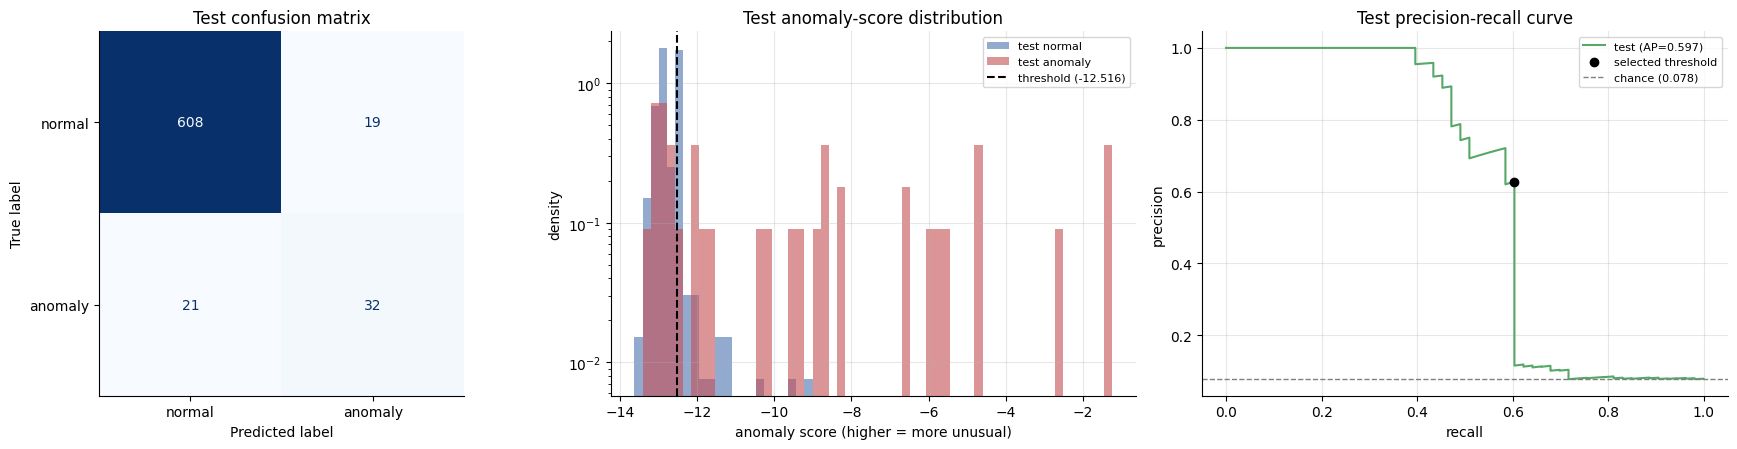

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))

ConfusionMatrixDisplay(np.array([[test_metrics["tn"], test_metrics["fp"]], [test_metrics["fn"], test_metrics["tp"]]]),
                       display_labels=["normal", "anomaly"]).plot(ax=axes[0], colorbar=False, cmap="Blues")
axes[0].set_title("Test confusion matrix"); axes[0].grid(False)

bins = np.linspace(min(s_test.min(), best["s_fit"].min()), max(s_test.max(), best["s_fit"].max()), 60)
axes[1].hist(s_test[y_test == 0], bins=bins, alpha=0.6, color="#4C72B0", label="test normal", density=True)
axes[1].hist(s_test[y_test == 1], bins=bins, alpha=0.6, color="#C44E52", label="test anomaly", density=True)
axes[1].axvline(thr, color="black", ls="--", label=f"threshold ({thr:.3f})")
axes[1].set(title="Test anomaly-score distribution", xlabel="anomaly score (higher = more unusual)", ylabel="density")
axes[1].set_yscale("log"); axes[1].legend(fontsize=8)

p, rc, _ = precision_recall_curve(y_test, s_test)
axes[2].plot(rc, p, color="#55A868", label=f"test (AP={test_metrics['PR_AUC']:.3f})")
axes[2].scatter([test_metrics["recall"]], [test_metrics["precision"]], color="black", zorder=3,
                label="selected threshold")
axes[2].axhline(y_test.mean(), ls="--", color="grey", lw=1, label=f"chance ({y_test.mean():.3f})")
axes[2].set(title="Test precision-recall curve", xlabel="recall", ylabel="precision"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [22]:
test_flag = s_test > thr
by_type = (pd.DataFrame({"type": test.loc[test.is_anomaly == 1, "anomaly_type"].to_numpy(),
                         "detected": test_flag[y_test == 1]})
             .groupby("type")["detected"].agg(days="size", detected="sum", recall="mean"))
display(by_type.round(2))

ep = (pd.DataFrame({"episode": test.loc[test.is_anomaly == 1, "episode_id"].to_numpy(),
                    "detected": test_flag[y_test == 1]})
        .groupby("episode")["detected"].any())
print(f"Test episodes detected (>= 1 flagged day): {ep.sum()} of {len(ep)} ({ep.mean():.1%})")

fp_rows = test[(y_test == 0) & test_flag]
print(f"False alarms: {len(fp_rows)} child-days across {fp_rows.child_id.nunique()} children "
      f"({len(fp_rows) / (y_test == 0).sum():.2%} of normal test days)")

,days,detected,recall
type,,,
bullying_run,19,2,0.11
grooming_burst,15,15,1.00
late_night_violence,9,8,0.89
self_harm_day,6,6,1.00
volume_spike,4,1,0.25


Test episodes detected (>= 1 flagged day): 16 of 22 (72.7%)
False alarms: 19 child-days across 10 children (3.03% of normal test days)


Test metrics are the single final estimate (typically below validation, which was used
for tuning). **Synthetic data:** not real-world accuracy; real use needs re-validation and
re-calibration on consented, anonymised C1/C2 output.

## 8. Model saving

`models/behavioral_anomaly_pipeline.pkl` (imputer → scaler → One-Class SVM) and
`models/behavioral_anomaly_metadata.json` (features, threshold, parameters, metrics,
versions, dataset hash). Load with `src.behavioral_anomaly.load_artifacts()` /
`predict_anomalies()`.

In [23]:
metadata = {
    "function": "Function 2 - Behavioral Anomaly Detection",
    "disclaimer": ("Trained and evaluated on SYNTHETIC data (behavioral_daily.csv). "
                   "Metrics do not establish real-world detection accuracy."),
    "sklearn_version": sklearn.__version__,
    "trained_on": DATA_PATH.name,
    "dataset_sha256": sha,
    "generator_version": meta["generator_version"],
    "seed": SEED,
    "algorithm": BEST[0],
    "feature_set": BEST[1],
    "n_features": len(feats),
    "features": feats,
    "params": best["params"],
    "pipeline_steps": [name for name, _ in best["pipe"].steps],
    "score": "anomaly_score = -pipeline.score_samples(X); higher = more anomalous",
    "threshold": best["best"]["threshold"],
    "threshold_quantile": best["best"]["quantile"],
    "threshold_rule": "flag a day when anomaly_score > threshold (quantile of normal training-day scores)",
    "training_rows": {"definition": "split == train, baseline_ready, is_anomaly == 0",
                      "n": int(len(fit_rows)),
                      "dates": [str(fit_rows.date.min().date()), str(fit_rows.date.max().date())]},
    "selection": "validation F1, then validation PR-AUC, then fewer features",
    "validation": {k: best["best"][k] for k in ("precision", "recall", "f1", "tp", "fp", "fn", "tn")}
                  | {"PR_AUC": float(best_row.val_PR_AUC), "n": int(len(val)), "anomalies": int(y_val.sum())},
    "test": test_metrics | {"n": int(len(test)), "anomalies": int(y_test.sum()),
                            "f1_ci95": [float(ci.loc["f1", "CI 2.5%"]), float(ci.loc["f1", "CI 97.5%"])]},
    "comparison": comparison[["algorithm", "feature_set", "n_features", "precision", "recall", "f1",
                              "val_PR_AUC", "threshold_quantile", "selected_threshold"]].to_dict("records"),
}
BA.save_artifacts(best["pipe"], metadata, MODEL_DIR)
for f in (BA.PIPELINE_FILE, BA.METADATA_FILE):
    print(f"saved {MODEL_DIR / f}  ({(MODEL_DIR / f).stat().st_size / 1024:.1f} KB)")

saved E:\RP-J26-DS-316\component4_profiling_xai\models\behavioral_anomaly_pipeline.pkl  (8.9 KB)
saved E:\RP-J26-DS-316\component4_profiling_xai\models\behavioral_anomaly_metadata.json  (3.9 KB)


In [24]:
pipe_loaded, meta_loaded = BA.load_artifacts(MODEL_DIR)
reloaded = BA.predict_anomalies(test, MODEL_DIR)
assert np.allclose(reloaded["anomaly_score"].to_numpy(), s_test)
assert (reloaded["is_flagged"].to_numpy() == test_flag).all()
assert meta_loaded["features"] == feats and meta_loaded["threshold"] == thr
print("Reloaded model reproduces the test scores and flags.")
reloaded.sort_values("anomaly_score", ascending=False).head(10)

Reloaded model reproduces the test scores and flags.


,child_id,date,anomaly_score,is_flagged
793,C009,2026-09-12,-1.240141,True
794,C009,2026-09-13,-1.297680,True
3323,C037,2026-09-22,-1.338964,True
3322,C037,2026-09-21,-1.353297,True
988,C011,2026-09-27,-2.524615,True
2150,C024,2026-09-19,-4.698007,True
1614,C018,2026-09-23,-4.713257,True
1615,C018,2026-09-24,-4.713903,True
2149,C024,2026-09-18,-4.716375,True
897,C010,2026-09-26,-5.465024,True


## Summary

- Set A = 27 daily features; Set B = 45. No leakage found.
- Selected: **One-Class SVM, Set A** (`nu=0.01`, `gamma=0.001`), threshold = 0.97 quantile of normal training scores.
- Test (synthetic): precision **0.627**, recall **0.604**, F1 **0.615**.
- Comparison table: `outputs/behavioral_anomaly_validation_comparison.csv`.
- All figures are from synthetic data.